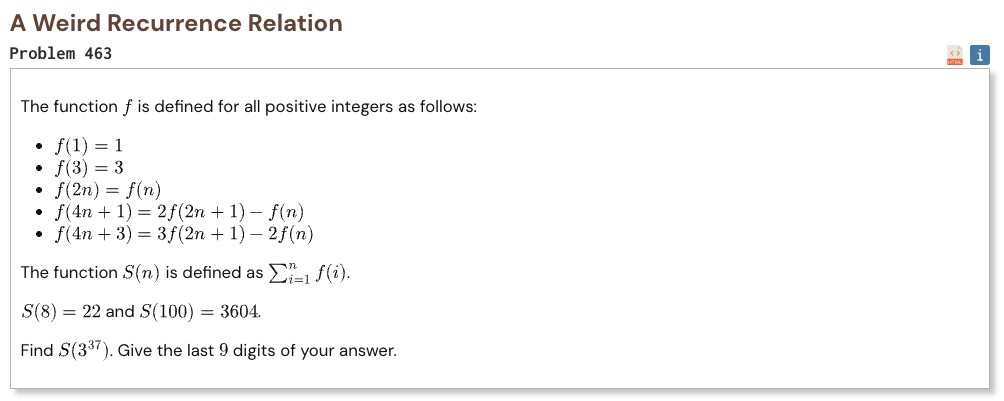

## Initial approach

-   the recurrence reduces every value of f to much smaller arguments
-   instead of generating every f value up to the huge target, derive formulas directly for the prefix sum S
-   split S into four cases depending on the remainder when n is divided by 4
-   each case only needs smaller values such as S of n divided by 2 and S of n divided by 4
-   keep separate memo dictionaries for f and S so repeated recursive calls are reused
-   the recursion depth stays very small because the arguments shrink by roughly a factor of two
-   calculate S at 3 to the power 37 and keep only the last 9 digits

In [1]:
%%time

MOD = 10**9

f_cache = {
    1: 1,
    3: 3
}

s_cache = {
    0: 0,
    1: 1,
    2: 2,
    3: 5
}

def f(n):
    if n in f_cache:
        return f_cache[n]

    if n % 2 == 0:
        result = f(n // 2)

    elif n % 4 == 1:
        k = (n - 1) // 4
        result = 2 * f(2 * k + 1) - f(k)

    else:
        k = (n - 3) // 4
        result = 3 * f(2 * k + 1) - 2 * f(k)

    f_cache[n] = result

    return result

def S(n):
    if n in s_cache:
        return s_cache[n]

    k, remainder = divmod(n, 4)

    base = 6 * S(2 * k) - 8 * S(k)

    if remainder == 0:
        result = base + 3 * f(k) - 1

    elif remainder == 1:
        result = base + 2 * f(k) + 2 * f(2 * k + 1) - 1

    elif remainder == 2:
        result = base + 2 * f(k) + 3 * f(2 * k + 1) - 1

    else:
        result = base + 6 * f(2 * k + 1) - 1

    s_cache[n] = result

    return result

n = 3**37
result = S(n) % MOD

print("Result:", result)

Result: 808981553
CPU times: user 295 μs, sys: 32 μs, total: 327 μs
Wall time: 329 μs
